# Body density

A student found that the bodies an NDE population starts with are not spread evenly around the core: a top-down heat map of 100 random bodies showed one side much brighter than the other. This notebook reproduces that picture for every genotype ARIEL has, from six sides, so a bias in a genotype or its decoder shows as an uneven picture.

How the picture is made. Each genotype here is drawn at random 100 times, decoded into a body graph, and built with `construct_mjspec_from_graph`. MuJoCo then places every module in its rest pose (`mj_forward`, no simulation), with the core at the origin. For each view, every module's box is projected onto the plane facing that view and painted into a 160 by 160 pixel mask of that one body. The 100 masks are averaged, so a pixel holds the fraction of bodies that have a module there (1.0, white, under the core, which every body has).

The views are named in the core's own frame: the core's FRONT face points to +y, RIGHT to +x, and up is +z. Each picture is drawn as a viewer standing on that side would see it, so in the top view the front is up and the right is on the right, and in the front view the robot's right is on the viewer's left. A pixel counts a module whether or not another module hides it, so opposite views (top and bottom, front and back, left and right) show the same shape mirrored. All six are drawn because they are quick to check side by side.

A second check counts which of the core's four faces (FRONT, BACK, RIGHT, LEFT) carry a module. A genotype with no preferred direction uses each face about equally often.

In [1]:
# Standard library
import random
from collections import Counter
from collections.abc import Callable

# Third-party libraries
import matplotlib.pyplot as plt
import mujoco
import networkx as nx
import numpy as np
import numpy.typing as npt
import torch
from PIL import Image, ImageDraw
from rich.table import Table

In [2]:
# Local libraries
from ariel import console
from ariel.body_phenotypes import (
    NUM_OF_FACES,
    NUM_OF_ROTATIONS,
    NUM_OF_TYPES_OF_MODULES,
    Genome,
    MorphologyDecoderBestFirst,
    construct_mjspec_from_graph,
    find_overlaps,
)
from ariel.body_phenotypes.robogen_lite.decoders import (
    HighProbabilityDecoder,
    VectorDecoder,
)
from ariel.ec.genotypes.nde import NeuralDevelopmentalEncoding
from ariel.ec.genotypes.tree import random_tree
from ariel.simulators import compile_model

In [3]:
# Settings
SEED = 42
BODIES = 100  # random genotypes per kind
MODULES = 30  # module budget of every decoder, core included
GENES = 64  # length of each NDE chromosome
WIDE = 8192  # gene range of the A3 course template, U(-WIDE, WIDE)
PIXELS = 160  # side of each density picture
HALF = 0.5  # metres shown on each side of the core

RNG = np.random.default_rng(SEED)
random.seed(SEED)  # random_tree and Genome.random draw from random
torch.manual_seed(SEED)  # NDE weights come from torch's default init
plt.rcParams["figure.dpi"] = 60  # keeps the saved notebook small
%config InlineBackend.figure_formats = ["jpeg"]  # half the size of PNG

## The genotypes

Eight ways to get a random body, one function each. Every function returns the body graph.

* **NDE, one network per body.** Three chromosomes of 64 genes go through a `NeuralDevelopmentalEncoding` with fresh random weights, and `HighProbabilityDecoder` (HPD) turns its three probability matrices into a graph. This is what `examples/z_ec_course/A3_template.py` and the `nde` notebook do: a new network for every body. Two gene ranges: U(0, 1) and the template's U(-8192, 8192).
* **NDE, one network for the population.** The same, but all 100 bodies share one network, as they would in an evolutionary run, where the network is the fixed map from genotype to body and only the genes evolve. Same two gene ranges.
* **Random matrices + HPD.** Uniform random probability matrices straight into HPD, no network.
* **Vector decoder.** Three vectors of U(0, 1) values into `VectorDecoder`.
* **CPPN best-first.** A random CPPN `Genome` (6 inputs: parent and child grid position; one connection score, 4 type and 3 rotation outputs) into `MorphologyDecoderBestFirst`.
* **Tree genome.** `random_tree`, which adds each module on a free face picked uniformly at random. It has no reason to prefer a side, so it is the reference picture.

In [4]:
SHARED_NDE = NeuralDevelopmentalEncoding(number_of_modules=MODULES)


def nde_genes(*, wide: bool) -> list[npt.NDArray[np.float32]]:
    low = -WIDE if wide else 0.0
    high = WIDE if wide else 1.0
    return [RNG.uniform(low, high, GENES).astype(np.float32) for _ in range(3)]


def nde_body(*, wide: bool, shared: bool) -> nx.DiGraph:
    nde = SHARED_NDE if shared else NeuralDevelopmentalEncoding(MODULES)
    types, connections, rotations = nde.forward(nde_genes(wide=wide))
    return HighProbabilityDecoder(MODULES).probability_matrices_to_graph(
        types, connections, rotations
    )


def matrices_body() -> nx.DiGraph:
    types = RNG.random((MODULES, NUM_OF_TYPES_OF_MODULES), dtype=np.float32)
    connections = RNG.random((MODULES, MODULES, NUM_OF_FACES), dtype=np.float32)
    rotations = RNG.random((MODULES, NUM_OF_ROTATIONS), dtype=np.float32)
    return HighProbabilityDecoder(MODULES).probability_matrices_to_graph(
        types, connections, rotations
    )


def vector_body() -> nx.DiGraph:
    vectors = [RNG.random(MODULES - 1) for _ in range(3)]
    return VectorDecoder(MODULES).vectors_to_graph(*vectors)


def cppn_body() -> nx.DiGraph:
    outputs = 1 + NUM_OF_TYPES_OF_MODULES + NUM_OF_ROTATIONS
    genome = Genome.random(6, outputs, 6 + outputs, 0)
    return MorphologyDecoderBestFirst(genome, max_modules=MODULES).decode()


def tree_body() -> nx.DiGraph:
    return random_tree(MODULES - 1).to_networkx()


GENOTYPES: dict[str, Callable[[], nx.DiGraph]] = {
    "NDE per body, genes U(0, 1)": lambda: nde_body(wide=False, shared=False),
    "NDE per body, genes U(-8192, 8192)": lambda: nde_body(
        wide=True, shared=False
    ),
    "NDE shared, genes U(0, 1)": lambda: nde_body(wide=False, shared=True),
    "NDE shared, genes U(-8192, 8192)": lambda: nde_body(
        wide=True, shared=True
    ),
    "random matrices + HPD": matrices_body,
    "vector decoder": vector_body,
    "CPPN best-first": cppn_body,
    "tree genome": tree_body,
}

In [5]:
# Checks: every genotype gives a body graph with the core at node 0 and
# at most MODULES modules; the random states are put back, so the
# pictures below do not change
states = RNG.bit_generator.state, random.getstate(), torch.get_rng_state()
for name, make_body in GENOTYPES.items():
    sample = make_body()
    assert sample.nodes[0]["type"] == "CORE", name
    assert 1 <= len(sample) <= MODULES, name
RNG.bit_generator.state = states[0]
random.setstate(states[1])
torch.set_rng_state(states[2])

## Projecting a body

`module_boxes` builds a body and returns the eight corners of every geom's box, in world coordinates with the core at the origin. `view_masks` paints those boxes into one mask per view. A box's outline on a plane is the union of its six faces projected onto it, so each face is painted as a filled quadrilateral.

`VIEWS` gives, for each view, which world axis runs to the right of the picture and which runs up, each with a sign: in the front view the viewer faces -y, so +x (the robot's right) runs to the viewer's left, sign -1.

In [6]:
CORNERS = np.array([
    [x, y, z] for x in (-1, 1) for y in (-1, 1) for z in (-1, 1)
])
BOX_FACES = [
    [0, 1, 3, 2],
    [4, 5, 7, 6],
    [0, 1, 5, 4],
    [2, 3, 7, 6],
    [0, 2, 6, 4],
    [1, 3, 7, 5],
]
X, Y, Z = 0, 1, 2
# view: (axis to the right, its sign, axis up, its sign)
VIEWS = {
    "top": (X, 1, Y, 1),
    "bottom": (X, -1, Y, 1),
    "front": (X, -1, Z, 1),
    "back": (X, 1, Z, 1),
    "left": (Y, -1, Z, 1),
    "right": (Y, 1, Z, 1),
}
CORE_FACES = ("FRONT", "BACK", "RIGHT", "LEFT")


def module_boxes(graph: nx.DiGraph) -> npt.NDArray[np.float64]:
    model = compile_model(construct_mjspec_from_graph(graph).spec)
    data = mujoco.MjData(model)
    mujoco.mj_forward(model, data)
    boxes = [
        data.geom_xpos[geom]
        + (CORNERS * model.geom_size[geom])
        @ data.geom_xmat[geom].reshape(3, 3).T
        for geom in range(model.ngeom)
    ]
    return np.array(boxes) - data.geom_xpos[0]  # geom 0 is the core


def view_masks(
    boxes: npt.NDArray[np.float64],
) -> dict[str, npt.NDArray[np.float64]]:
    masks = {}
    for view, (right, right_sign, up, up_sign) in VIEWS.items():
        image = Image.new("1", (PIXELS, PIXELS), 0)
        draw = ImageDraw.Draw(image)
        for corners in boxes:
            columns = (right_sign * corners[:, right] / HALF + 1) / 2 * PIXELS
            rows = (1 - up_sign * corners[:, up] / HALF) / 2 * PIXELS
            for face in BOX_FACES:
                draw.polygon(
                    list(zip(columns[face], rows[face], strict=True)), fill=1
                )
        masks[view] = np.asarray(image, dtype=np.float64)
    return masks

Check the projection on a body whose layout is known: one brick on the core's FRONT face and one on its RIGHT face. In the top view the first should sit above the core and the second to its right; in the front view the right brick should sit on the viewer's left.

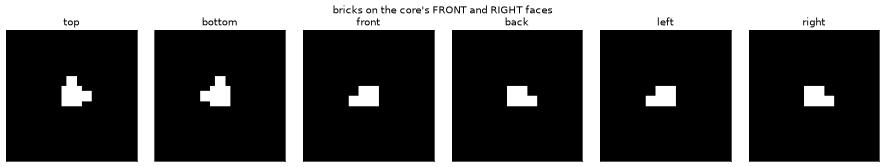

In [7]:
probe = nx.DiGraph()
probe.add_node(0, type="CORE", rotation="DEG_0")
probe.add_node(1, type="BRICK", rotation="DEG_0")
probe.add_node(2, type="BRICK", rotation="DEG_0")
probe.add_edge(0, 1, face="FRONT")
probe.add_edge(0, 2, face="RIGHT")
probe_masks = view_masks(module_boxes(probe))

fig, axes = plt.subplots(1, 6, figsize=(15, 2.8))
for axis, (view, mask) in zip(axes, probe_masks.items(), strict=True):
    axis.imshow(mask, cmap="gray", extent=(-HALF, HALF, -HALF, HALF))
    axis.set_title(view)
    axis.set_xticks([])
    axis.set_yticks([])
fig.suptitle("bricks on the core's FRONT and RIGHT faces")
plt.tight_layout()
plt.show()

In [8]:
middle = PIXELS // 2
step = PIXELS // 8  # 0.125 m, about one module from the core's centre
EDGE_PIXELS = 0.01  # share of pixels a mirror may differ by, see below
top, front = probe_masks["top"], probe_masks["front"]
assert top[middle - step, middle] == 1  # FRONT brick above the core
assert top[middle, middle + step] == 1  # RIGHT brick right of the core
assert top[middle + step, middle] == 0  # nothing behind
assert top[middle, middle - step] == 0  # nothing on the left
assert front[middle, middle - step] == 1  # robot's right on viewer's left
# Opposite views mirror each other, up to pixels on a box edge, which
# the polygon fill rounds differently on each side
assert np.mean(probe_masks["bottom"] != top[:, ::-1]) < EDGE_PIXELS

## Density of 100 random bodies per genotype

For every genotype: average the six masks of 100 bodies, count the core faces that carry a module, count how many of the 100 bodies are different graphs (same modules, types, rotations and faces), and count how many have two modules that overlap (`find_overlaps`: two modules that are not neighbours penetrating deeper than 1% of the smaller one's thinnest side). Overlap repair is off here, so the pictures show the bodies as decoded; `body_density_repair` draws them with the repair on. One figure per genotype, all on the same colour scale.

In [9]:
type Density = dict[str, npt.NDArray[np.float64]]


def body_key(graph: nx.DiGraph) -> tuple[object, ...]:
    nodes = sorted(
        (n, d["type"], d["rotation"]) for n, d in graph.nodes(data=True)
    )
    edges = sorted((a, b, d["face"]) for a, b, d in graph.edges(data=True))
    return (tuple(nodes), tuple(edges))


densities: dict[str, Density] = {}
core_faces: dict[str, Counter[str]] = {}
distinct: dict[str, int] = {}
sizes: dict[str, float] = {}
overlapping: dict[str, int] = {}
for name, make_body in GENOTYPES.items():
    total = {view: np.zeros((PIXELS, PIXELS)) for view in VIEWS}
    faces: Counter[str] = Counter()
    keys = set()
    lengths = []
    clashes = 0
    for _ in range(BODIES):
        graph = make_body()
        clashes += bool(
            find_overlaps(graph, construct_mjspec_from_graph(graph))
        )
        keys.add(body_key(graph))
        lengths.append(len(graph))
        faces.update(d["face"] for _, _, d in graph.out_edges(0, data=True))
        for view, mask in view_masks(module_boxes(graph)).items():
            total[view] += mask
    densities[name] = {view: t / BODIES for view, t in total.items()}
    core_faces[name] = faces
    distinct[name] = len(keys)
    sizes[name] = float(np.mean(lengths))
    overlapping[name] = clashes

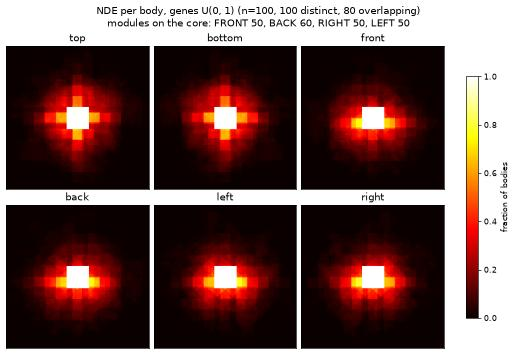

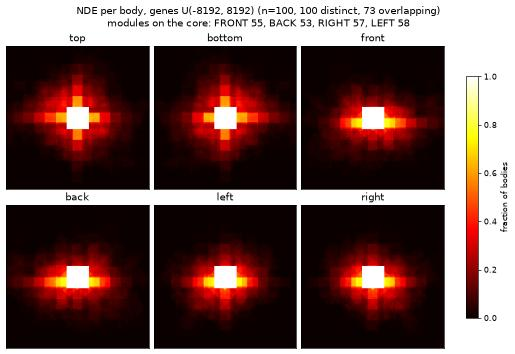

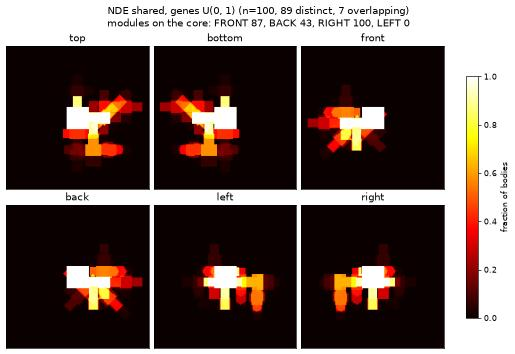

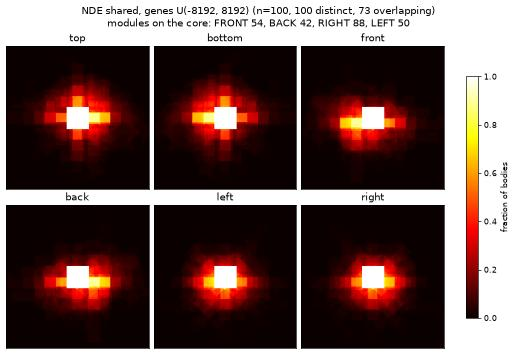

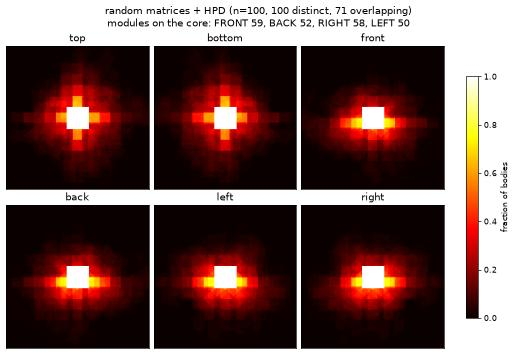

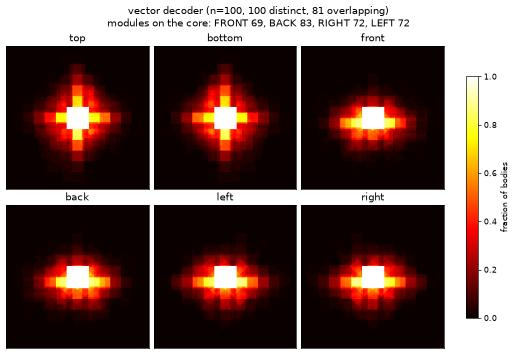

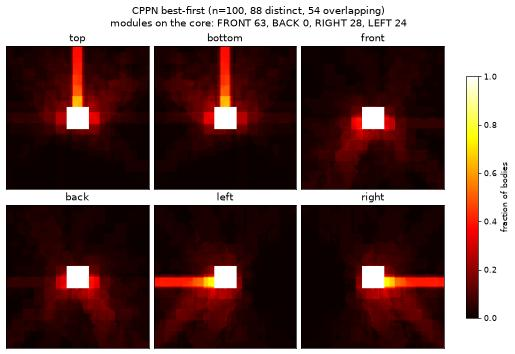

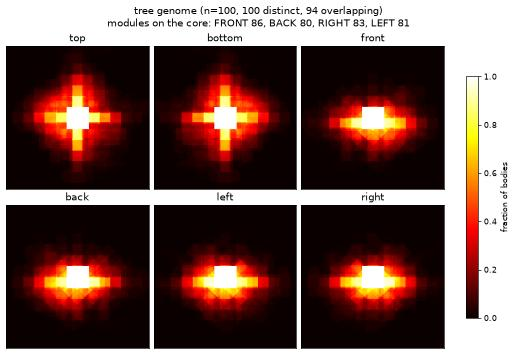

In [10]:
def plot_density(name: str, density: Density) -> None:
    fig, axes = plt.subplots(2, 3, figsize=(8.5, 5.8), layout="constrained")
    for axis, (view, picture) in zip(axes.flat, density.items(), strict=True):
        image = axis.imshow(
            picture,
            cmap="hot",
            vmin=0,
            vmax=1,
            extent=(-HALF, HALF, -HALF, HALF),
        )
        axis.set_title(view)
        axis.set_xticks([])
        axis.set_yticks([])
    fig.colorbar(image, ax=axes, label="fraction of bodies", shrink=0.8)
    faces = ", ".join(f"{f} {core_faces[name][f]}" for f in CORE_FACES)
    fig.suptitle(
        f"{name} (n={BODIES}, {distinct[name]} distinct, "
        f"{overlapping[name]} overlapping)\n"
        f"modules on the core: {faces}"
    )
    plt.show()


for name, density in densities.items():
    plot_density(name, density)

In [11]:
# Checks: every picture has the core in its centre, and opposite views
# mirror each other up to the pixels on box edges
for density in densities.values():
    for view in VIEWS:
        assert density[view].shape == (PIXELS, PIXELS)
        assert density[view][middle, middle] == 1  # every body has its core
    for first, second in (
        ("top", "bottom"),
        ("front", "back"),
        ("right", "left"),
    ):
        mirrored = density[second][:, ::-1]
        assert np.mean(np.abs(density[first] - mirrored)) < EDGE_PIXELS

## Core faces and diversity, side by side

A body uses at most one module per core face, so each count is out of 100. "overlapping" is the number of the 100 bodies with at least one overlapping pair. The last column is the largest count divided by the smallest: 1.0 means the four sides are used equally, and infinite means one side is never used.

In [12]:
table = Table(title=f"Modules on each core face, {BODIES} bodies per genotype")
table.add_column("genotype")
for face in CORE_FACES:
    table.add_column(face, justify="right")
table.add_column("distinct", justify="right")
table.add_column("modules", justify="right")
table.add_column("overlapping", justify="right")
table.add_column("max/min", justify="right")
for name, faces in core_faces.items():
    counts = [faces[face] for face in CORE_FACES]
    spread = max(counts) / min(counts) if min(counts) else float("inf")
    table.add_row(
        name,
        *map(str, counts),
        str(distinct[name]),
        f"{sizes[name]:.1f}",
        str(overlapping[name]),
        f"{spread:.2f}",
    )
console.print(table)

                               Modules on each core face, 100 bodies per genotype                                
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┳━━━━━━┳━━━━━━━┳━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ genotype                           ┃ FRONT ┃ BACK ┃ RIGHT ┃ LEFT ┃ distinct ┃ modules ┃ overlapping ┃ max/min ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━╇━━━━━━━╇━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━┩
│ NDE per body, genes U(0, 1)        │    50 │   60 │    50 │   50 │      100 │    20.4 │          80 │    1.20 │
│ NDE per body, genes U(-8192, 8192) │    55 │   53 │    57 │   58 │      100 │    20.2 │          73 │    1.09 │
│ NDE shared, genes U(0, 1)          │    87 │   43 │   100 │    0 │       89 │    16.0 │           7 │     inf │
│ NDE shared, genes U(-8192, 8192)   │    54 │   42 │    88 │   50 │      100 │    16.2 │          73 │    2.10 │
│ random matrices + HPD              │    59 │   52 │    58 │   50 │      100 │    20.5 │          71 │    1.18 │
│ vector decoder                     │    69 │   83 │    72 │   72 │      100 │    20.7 │          81 │    1.20 │
│ CPPN best-first                    │    63 │    0 │    28 │   24 │       88 │    30.0 │          54 │     inf │
│ tree genome                        │    86 │   80 │    83 │   81 │      100 │    30.0 │          94 │    1.07 │
└────────────────────────────────────┴───────┴──────┴───────┴──────┴──────────┴─────────┴─────────────┴─────────┘

In [13]:
# Checks: the tree genome uses every core face in at least half its
# bodies, its 100 bodies all differ, and most of them overlap (the
# repair is off here); the NDE with one network per body also gives
# 100 different bodies
tree = core_faces["tree genome"]
assert all(tree[face] >= BODIES // 2 for face in CORE_FACES)
assert distinct["tree genome"] == BODIES
assert overlapping["tree genome"] > BODIES // 2
assert distinct["NDE per body, genes U(0, 1)"] == BODIES

## What the pictures show

The tree genome is the reference: 80 to 86 of 100 bodies use each core face, and its six pictures are symmetric. The vector decoder, random matrices with HPD, and the NDE with a new network per body come close to that (their counts are lower because their bodies are smaller: HPD and the vector decoder drop modules decoded as NONE, about 20 modules of 30 kept). Most bodies of every genotype have overlapping modules (54 to 94 of 100; 7 for the shared network with genes in U(0, 1), whose bodies are smaller and alike), so the pictures count some modules that share space with another.

Two genotypes do not.

**NDE with one network for the population.** With genes in U(0, 1), all 100 random bodies have a module on the core's RIGHT face and none has one on its LEFT face. The graphs differ further out (89 of 100 are distinct), but near the core they share one layout, which the pictures show as sharp bright shapes instead of a blur. One network maps every genotype in that range to similar probability matrices, and HPD, which takes the largest probability at every step, then makes the same first choices. With the template's wide gene range the bias is weaker but still there: 88 bodies use RIGHT and 42 use BACK, the lopsided top view of the student's picture. A fresh network per body, as in the template and the `nde` notebook, hides this, because the random weights then do the varying, not the genes; but an evolutionary run has to keep one network, or a child would not inherit its parent's body. This is the most likely cause of the student's picture, though without their code it is not certain their run used one network.

**CPPN best-first.** The core's BACK face never carries a module. `MorphologyDecoderBestFirst.decode` accepts a candidate only when `face in ALLOWED_FACES[child_type]`, which checks the parent's face against the faces the child allows. No child type allows BACK (a brick has FRONT, RIGHT, LEFT, TOP, BOTTOM; a hinge only FRONT), so nothing ever attaches to a BACK face, and hinges attach only to FRONT faces.

The checks below pin both problems as they are today. When a fix lands they fail, and should be turned around.

In [14]:
# Known problems, as they are today (see PLAN.md Known problems)
shared = core_faces["NDE shared, genes U(0, 1)"]
assert shared["RIGHT"] == BODIES
assert shared["LEFT"] == 0
wide = core_faces["NDE shared, genes U(-8192, 8192)"]
assert max(wide.values()) >= 2 * min(wide.values())
assert core_faces["CPPN best-first"]["BACK"] == 0